# Water Guardian: three-class ML Monitor
**Google Colab notebook · prepared 13 October 2026**

Train **Logistic Regression** and **Random Forest** to distinguish `normal`, `leak`, and `sensor_fault` from measured pressure and flow.

This notebook audits the source files, prepares a combined dataset, runs your eight requested evaluation configurations for both models, and exports a portable scikit-learn pipeline for the existing FastAPI app. A CPU runtime is sufficient. No Groq, Gemini or other API key is used for ML training.

**Run in Colab:** upload this `.ipynb` through **File → Upload notebook**, select a CPU runtime, and choose **Runtime → Run all**. If setup installs packages, it stops: choose **Runtime → Restart session**, then **Runtime → Run all** again. A restart is required before importing the changed NumPy packages. The default data mode downloads the authors' public ZIP automatically. Local execution detects this project's existing dataset.

Sources: [dataset and licence](https://github.com/Moazeni-s-Concise-Lab/WDSEventDB), [authors' paper and label definitions](https://www.researchgate.net/publication/404116448_WDSEventDB_A_Real-Time_Benchmark_Dataset_for_Event_Diagnosis_in_Water_Distribution_Networks), [scikit-learn grouped evaluation](https://scikit-learn.org/stable/modules/cross_validation.html#cross-validation-iterators-for-grouped-data).


## 1. How eight Excel files become one training table

Use **Clean (1 file), Leakage (3 files), and Sensor Failure (4 files)**. Cyberattack remains outside the three-class training task.

All selected files have the same column layout. We stack their rows **vertically** with `pd.concat`; we do not join readings from different experiments side by side. Every resulting row still represents one recorded sample from one experiment. The eight originals remain unchanged. A combined CSV is exported for inspection; creating a merged Excel workbook is unnecessary.

The authors define `Labels = 0` as normal and `Labels = 1` as an abnormal event. The event folder gives the abnormal event type:

* Any selected file, original label 0 → target 0 (`normal`).
* Leakage file, original label 1 → target 1 (`leak`).
* Sensor Failure file, original label 1 → target 2 (`sensor_fault`).

Do **not** label an entire Leakage file as leaking: its normal periods stay normal. For example, the local `LeakEvent1.xlsx` contains 540 normal samples followed by 828 event samples.

We retain `recording_id`, source category, original label and sample index for traceability and splitting. **Only eight pressure/flow columns enter the model.** File names, folder names, labels, sample index, township zones and recording IDs never enter its features.


## 2. Experiment design: your eight configurations

Both models run **70/30**, **80/20**, **5-fold CV**, **10-fold CV**, **70/30 + 5-fold CV**, **70/30 + 10-fold CV**, **80/20 + 5-fold CV**, and **80/20 + 10-fold CV**: 16 comparison rows in total.

* **70/30 or 80/20:** stratified sample split, fixed model settings, score the reserved development test portion.
* **CV alone:** fixed settings, stratified CV, score out-of-fold predictions. Every development sample is predicted by a model that did not train on that row.
* **Split + CV:** CV tunes hyperparameters **inside the training portion only**, then the best pipeline is evaluated once on its reserved development test portion. CV scores and test scores are separate columns.

**These requested comparisons are sample-level development experiments.** Adjacent time-series samples may appear in different folds, so their scores can overstate performance on a new recording. They are not evidence of performance in a real township.

To provide a stronger final result, reserve `LeakEvent3.xlsx` and `SensorEvent67.xlsx` **before all eight experiments**. All requested comparisons use the other six recordings. A separate shared 5-fold development search selects the model and its settings; the two unseen recordings are then evaluated once. The final test never enters learned imputation statistics, scaling, training, CV or model selection.

There are only eight source recordings, so 10-fold **recording-level** CV is impossible; even 5 folds cannot all contain a leak recording because there are only three leak files. The requested 5/10-fold runs are deliberately labelled **stratified sample CV**. Do not rename them grouped CV.


In [ ]:
import importlib.util
from importlib.metadata import PackageNotFoundError, version
import subprocess
import sys

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
SETUP_REQUIRES_RESTART = False
if IN_COLAB:
    # Check metadata without importing NumPy into this session.
    pins = {"scikit-learn": "1.9.1", "pandas": "2.3.3",
            "numpy": "2.3.5", "openpyxl": "3.1.5", "joblib": "1.6.0"}
    try:
        versions_match = all(version(name) == wanted for name, wanted in pins.items())
    except PackageNotFoundError:
        versions_match = False
    # A fresh process also catches mixed/broken installations.
    health = subprocess.run([sys.executable, "-c",
        "import numpy, scipy, pandas, sklearn, openpyxl, joblib, matplotlib, seaborn"],
        capture_output=True, text=True) if versions_match else None
    if not versions_match or health.returncode != 0:
        SETUP_REQUIRES_RESTART = True
        subprocess.check_call([sys.executable, "-m", "pip", "install",
            "--no-cache-dir", "--force-reinstall",
            *[f"{name}=={wanted}" for name, wanted in pins.items()],
            "matplotlib>=3.9,<4", "seaborn>=0.13,<0.14"])
        raise SystemExit("Setup finished. Choose Runtime > Restart session, then Run all again.")
print("Colab runtime:", IN_COLAB)


In [2]:
if SETUP_REQUIRES_RESTART:
    raise SystemExit("Choose Runtime > Restart session, then Run all before importing packages.")

import hashlib
import json
import math
import platform
import shutil
import time
import urllib.request
import zipfile
from pathlib import Path, PurePosixPath

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
from IPython.display import display
from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, average_precision_score,
    classification_report, confusion_matrix, f1_score,
    precision_recall_fscore_support, roc_auc_score, ConfusionMatrixDisplay)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_predict, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

DATA_MODE = "auto"  # auto | github | upload | local
LOCAL_DATA_DIR = None  # Optional local path; Windows paths cannot be used inside Colab.
SEED = 42
CV_JOBS = 2
RF_TREES = 100
FINAL_TEST_RECORDINGS = ["Leakage/LeakEvent3.xlsx", "Sensor Failure/SensorEvent67.xlsx"]

OUTPUT_DIR = Path("/content/water_guardian_ml_outputs") if IN_COLAB else Path.cwd() / "work" / "ml-notebook-validation"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
FEATURES = ["Pressure 1 Out", "Pressure 2 Out", "Pressure 3 In", "Pressure 4 In",
            "Water Flow 1", "Water Flow 2", "Water Flow 3", "Water Flow 4"]
ALL_CHANNELS = FEATURES + ["VFD 1", "VFD 2", "VFD 3", "VFD 4-1", "VFD 4-2", "Analog Valve 1", "Analog Valve 2"]
CLASS_MAP = {0: "normal", 1: "leak", 2: "sensor_fault"}
CLASS_IDS = [0, 1, 2]
CLASS_NAMES = [CLASS_MAP[i] for i in CLASS_IDS]
COLOURS = {"normal": "#789b8d", "leak": "#bf846d", "sensor_fault": "#698fae"}

sns.set_theme(style="whitegrid", palette=["#698fae", "#b79c7d"], font_scale=1.0)
pd.set_option("display.max_columns", 24)
pd.set_option("display.max_colwidth", 75)
VERSIONS = {"python": platform.python_version(), "sklearn": sklearn.__version__,
    "pandas": pd.__version__, "numpy": np.__version__, "joblib": joblib.__version__}
print("Runtime versions:", VERSIONS)
print("Outputs:", OUTPUT_DIR)


Runtime versions: {'python': '3.12.14', 'sklearn': '1.9.1', 'pandas': '2.3.3', 'numpy': '2.3.5', 'joblib': '1.6.0'}
Outputs: D:\SCHOLARSHIPS\My Items\Degree Project\SDHackathon\work\ml-notebook-validation


## 3. Locate or download the original recordings

`auto` uses the existing local project folder when available; otherwise it downloads the public ZIP. In Colab you can change `DATA_MODE` to `upload` to upload the authors' ZIP instead. The extractor rejects unsafe paths and ignores macOS metadata. It does not alter any workbook.


In [3]:
DATA_URL = "https://raw.githubusercontent.com/Moazeni-s-Concise-Lab/WDSEventDB/main/WDSEventDB.zip"

def safe_extract(archive, destination):
    destination.mkdir(parents=True, exist_ok=True)
    root = destination.resolve()
    with zipfile.ZipFile(archive) as z:
        for member in z.infolist():
            relative = PurePosixPath(member.filename.replace("\\", "/"))
            if relative.is_absolute() or ".." in relative.parts:
                raise ValueError(f"Unsafe ZIP member: {member.filename}")
            if "__MACOSX" in relative.parts or relative.name.startswith("._"):
                continue
            target = (destination / str(relative)).resolve()
            if not target.is_relative_to(root):
                raise ValueError("ZIP extraction would leave the data folder")
            if member.is_dir():
                target.mkdir(parents=True, exist_ok=True)
            else:
                target.parent.mkdir(parents=True, exist_ok=True)
                with z.open(member) as src, target.open("wb") as dst:
                    shutil.copyfileobj(src, dst)

candidates = ([Path(LOCAL_DATA_DIR)] if LOCAL_DATA_DIR else []) + [Path.cwd() / "WDSEventDB", Path.cwd().parent / "WDSEventDB"]
local = next((p for p in candidates if p.exists() and any(p.rglob("CleanData.xlsx"))), None)
if DATA_MODE == "local" or (DATA_MODE == "auto" and local is not None):
    if local is None:
        raise FileNotFoundError("Set LOCAL_DATA_DIR to the local WDSEventDB folder.")
    data_root = local
else:
    cache = OUTPUT_DIR / "source_data"
    archive = cache / "WDSEventDB.zip"
    cache.mkdir(parents=True, exist_ok=True)
    if DATA_MODE == "upload":
        if not IN_COLAB:
            raise RuntimeError("Upload mode is for Colab. Use local mode on your PC.")
        from google.colab import files
        uploaded = files.upload()
        names = [name for name in uploaded if name.lower().endswith(".zip")]
        if len(names) != 1:
            raise ValueError("Upload exactly one WDSEventDB ZIP.")
        archive.write_bytes(uploaded[names[0]])
    elif DATA_MODE in {"auto", "github"}:
        urllib.request.urlretrieve(DATA_URL, archive)
    else:
        raise ValueError("Unknown DATA_MODE")
    safe_extract(archive, cache / "extracted")
    data_root = cache / "extracted"

source_files = sorted(p for p in data_root.rglob("*.xlsx")
    if "__MACOSX" not in p.parts and not p.name.startswith("._"))
selected_files = [p for p in source_files if p.parent.name in {"Clean", "Leakage", "Sensor Failure"}]
excluded_files = [p for p in source_files if p.parent.name == "Cyberattack"]
if not selected_files:
    raise FileNotFoundError("No selected recordings found. Preserve Clean, Leakage and Sensor Failure folder names.")
print("Selected:", [f"{p.parent.name}/{p.name}" for p in selected_files])
print("Excluded from training:", [p.name for p in excluded_files])


Selected: ['Clean/CleanData.xlsx', 'Leakage/LeakEvent1.xlsx', 'Leakage/LeakEvent2.xlsx', 'Leakage/LeakEvent3.xlsx', 'Sensor Failure/SensorEvent1.xlsx', 'Sensor Failure/SensorEvent23.xlsx', 'Sensor Failure/SensorEvent45.xlsx', 'Sensor Failure/SensorEvent67.xlsx']
Excluded from training: ['CyberEvent1-4.xlsx']


## 4. Audit and cleaning policy

The notebook checks column names, required channels, missing cells, nonnumeric values, infinities, invalid targets, empty rows, repeated feature vectors, label conflicts and constant channels.

Cleaning rules:

* Trim column-name whitespace; fail on missing/duplicate required columns.
* Remove completely empty rows and rows with invalid original labels, recording exactly how many.
* Convert malformed/nonfinite sensor entries to missing values. Median imputation happens **inside each training pipeline**, never on the entire dataset before splitting.
* **Keep negative/extreme pressure readings.** The authors physically displaced pressure-sensor cables to emulate faults, producing large negative readings. Removing them as outliers would remove the phenomenon we want to detect.
* Keep legitimate zero readings. Pump-off states are not missing values.
* Keep repeated measurements at different sample indices. Quantised sensors can repeat naturally; `drop_duplicates()` on sensor values would erase real samples. Detect duplicated *whole source workbooks* and fail for review instead.
* Report ambiguous repeated feature vectors rather than quietly rewriting labels.

Pressure and flow units are documented as psi and cubic feet/minute (cfm); the source sampling interval is one second. Replayed arrival times in the app are not the source measurement times. See the authors' paper, Data Collection section.


In [4]:
parts, audit_rows, cleaning_rows = [], [], []
seen_hashes = {}
for p in selected_files:
    rid = f"{p.parent.name}/{p.name}"
    digest = hashlib.sha256(p.read_bytes()).hexdigest()
    if digest in seen_hashes:
        raise ValueError(f"Duplicated source workbook: {rid} and {seen_hashes[digest]}")
    seen_hashes[digest] = rid
    raw = pd.read_excel(p, sheet_name=0, engine="openpyxl")
    original_headers = list(raw.columns)
    raw.columns = [str(c).strip() for c in raw.columns]
    if raw.columns.duplicated().any():
        raise ValueError(f"Duplicate column names in {rid}")
    missing_columns = set(ALL_CHANNELS + ["Labels"]) - set(raw.columns)
    if missing_columns:
        raise ValueError(f"{rid}: missing required columns {sorted(missing_columns)}")
    sample_index = np.arange(len(raw))
    empty = raw[ALL_CHANNELS + ["Labels"]].isna().all(axis=1)
    frame = raw.loc[~empty, ALL_CHANNELS + ["Labels"]].copy()
    frame["sample_index"] = sample_index[~empty.to_numpy()]
    numeric = frame[ALL_CHANNELS].apply(pd.to_numeric, errors="coerce")
    original_missing = int(frame[ALL_CHANNELS].isna().sum().sum())
    malformed = int((numeric.isna() & frame[ALL_CHANNELS].notna()).sum().sum())
    infinite = int(np.isinf(numeric.to_numpy(dtype=float)).sum())
    numeric = numeric.replace([np.inf, -np.inf], np.nan)
    original_label = pd.to_numeric(frame["Labels"], errors="coerce")
    valid_label = original_label.isin([0, 1])
    invalid_labels = int((~valid_label).sum())
    if p.parent.name == "Clean" and (original_label.loc[valid_label] != 0).any():
        raise ValueError("CleanData has unexpected event labels. Review the dataset before continuing.")
    cleaned = numeric.loc[valid_label].copy()
    cleaned["sample_index"] = frame.loc[valid_label, "sample_index"].astype(int)
    cleaned["original_label"] = original_label.loc[valid_label].astype(int)
    event_class = 1 if p.parent.name == "Leakage" else 2 if p.parent.name == "Sensor Failure" else 0
    cleaned["target"] = np.where(cleaned["original_label"].eq(0), 0, event_class).astype(int)
    cleaned["recording_id"] = rid
    cleaned["source_category"] = p.parent.name
    cleaned["target_name"] = cleaned["target"].map(CLASS_MAP)
    audit_rows.append({"recording_id": rid, "original_rows": len(raw), "kept_rows": len(cleaned),
        "normal": int(cleaned.target.eq(0).sum()), "leak": int(cleaned.target.eq(1).sum()),
        "sensor_fault": int(cleaned.target.eq(2).sum()), "missing_sensor_cells": original_missing,
        "malformed_sensor_cells": malformed, "infinite_sensor_cells": infinite,
        "negative_pressure_cells": int(cleaned[FEATURES[:4]].lt(0).sum().sum()),
        "repeated_8channel_vectors": int(cleaned.duplicated(FEATURES).sum()), "sha256": digest})
    cleaning_rows.append({"recording_id": rid, "trimmed_headers": original_headers != list(raw.columns),
        "removed_empty_rows": int(empty.sum()), "removed_invalid_labels": invalid_labels,
        "converted_malformed_cells": malformed, "converted_infinite_cells": infinite,
        "imputation": "training-fold medians only", "removed_outliers": 0, "removed_repeated_measurements": 0})
    parts.append(cleaned)

combined = pd.concat(parts, ignore_index=True)
if combined.duplicated(["recording_id", "sample_index"]).any():
    raise ValueError("A source sample was loaded more than once")
source_audit = pd.DataFrame(audit_rows)
cleaning_log = pd.DataFrame(cleaning_rows)
feature_audit = pd.DataFrame({"missing": combined[ALL_CHANNELS].isna().sum(),
    "minimum": combined[ALL_CHANNELS].min(), "maximum": combined[ALL_CHANNELS].max(),
    "unique_values": combined[ALL_CHANNELS].nunique()})
feature_audit["constant"] = feature_audit.unique_values.le(1)
conflicts = combined.groupby(FEATURES, dropna=False)["target"].nunique()
print("Combined shape:", combined.shape, "| Classes:", combined.target_name.value_counts().to_dict())
print("Ambiguous identical 8-channel vectors:", int(conflicts.gt(1).sum()))
display(source_audit.drop(columns="sha256"))
display(cleaning_log)
display(feature_audit)
display(combined[FEATURES + ["original_label", "target_name", "recording_id", "sample_index"]].head())
source_audit.to_csv(OUTPUT_DIR / "source_audit.csv", index=False)
cleaning_log.to_csv(OUTPUT_DIR / "cleaning_log.csv", index=False)
feature_audit.to_csv(OUTPUT_DIR / "feature_audit.csv")
combined.to_csv(OUTPUT_DIR / "combined_cleaned.csv", index=False)

changes = int(cleaning_log[["removed_empty_rows", "removed_invalid_labels", "converted_malformed_cells", "converted_infinite_cells"]].to_numpy().sum())
print("Cleaning verdict:", "No row/value cleaning was needed; preprocessing remains inside pipelines." if changes == 0 else f"Audit recorded {changes} cleaning actions; review cleaning_log.csv.")


Combined shape: (19296, 21) | Classes: {'normal': 16548, 'leak': 2138, 'sensor_fault': 610}
Ambiguous identical 8-channel vectors: 0


,recording_id,original_rows,kept_rows,normal,leak,sensor_fault,missing_sensor_cells,malformed_sensor_cells,infinite_sensor_cells,negative_pressure_cells,repeated_8channel_vectors
0,Clean/CleanData.xlsx,9743,9743,9743,0,0,0,0,0,4250,0
1,Leakage/LeakEvent1.xlsx,1368,1368,540,828,0,0,0,0,0,0
2,Leakage/LeakEvent2.xlsx,1385,1385,771,614,0,0,0,0,10,20
3,Leakage/LeakEvent3.xlsx,1355,1355,659,696,0,0,0,0,202,0
4,Sensor Failure/SensorEvent1.xlsx,1360,1360,1183,0,177,0,0,0,371,0
5,Sensor Failure/SensorEvent23.xlsx,1362,1362,1210,0,152,0,0,0,343,0
6,Sensor Failure/SensorEvent45.xlsx,1361,1361,1202,0,159,0,0,0,335,0
7,Sensor Failure/SensorEvent67.xlsx,1362,1362,1240,0,122,0,0,0,313,0


,recording_id,trimmed_headers,removed_empty_rows,removed_invalid_labels,converted_malformed_cells,converted_infinite_cells,imputation,removed_outliers,removed_repeated_measurements
0,Clean/CleanData.xlsx,False,0,0,0,0,training-fold medians only,0,0
1,Leakage/LeakEvent1.xlsx,False,0,0,0,0,training-fold medians only,0,0
2,Leakage/LeakEvent2.xlsx,False,0,0,0,0,training-fold medians only,0,0
3,Leakage/LeakEvent3.xlsx,False,0,0,0,0,training-fold medians only,0,0
4,Sensor Failure/SensorEvent1.xlsx,False,0,0,0,0,training-fold medians only,0,0
5,Sensor Failure/SensorEvent23.xlsx,False,0,0,0,0,training-fold medians only,0,0
6,Sensor Failure/SensorEvent45.xlsx,False,0,0,0,0,training-fold medians only,0,0
7,Sensor Failure/SensorEvent67.xlsx,False,0,0,0,0,training-fold medians only,0,0


,missing,minimum,maximum,unique_values,constant
Pressure 1 Out,0,-13.277,10.210,1432,False
Pressure 2 Out,0,-12.720,2.461,1047,False
Pressure 3 In,0,-10.181,2.662,3083,False
Pressure 4 In,0,-13.276,3.039,3817,False
Water Flow 1,0,0.191,40.099,185,False
Water Flow 2,0,0.114,0.608,138,False
Water Flow 3,0,0.078,0.612,155,False
Water Flow 4,0,0.079,40.099,217,False
VFD 1,0,27.167,100.000,143,False
VFD 2,0,0.000,0.000,1,True


,Pressure 1 Out,Pressure 2 Out,Pressure 3 In,Pressure 4 In,Water Flow 1,Water Flow 2,Water Flow 3,Water Flow 4,original_label,target_name,recording_id,sample_index
0,5.170,1.745,1.274,1.651,0.371,0.389,0.334,0.489,0,normal,Clean/CleanData.xlsx,0
1,5.247,1.734,1.276,1.646,0.371,0.391,0.334,0.489,0,normal,Clean/CleanData.xlsx,1
2,5.364,1.727,1.267,1.634,0.397,0.391,0.333,0.486,0,normal,Clean/CleanData.xlsx,2
3,5.468,1.700,1.238,1.608,0.397,0.393,0.333,0.486,0,normal,Clean/CleanData.xlsx,3
4,5.423,1.670,1.214,1.586,0.405,0.389,0.333,0.486,0,normal,Clean/CleanData.xlsx,4


Cleaning verdict: No row/value cleaning was needed; preprocessing remains inside pipelines.


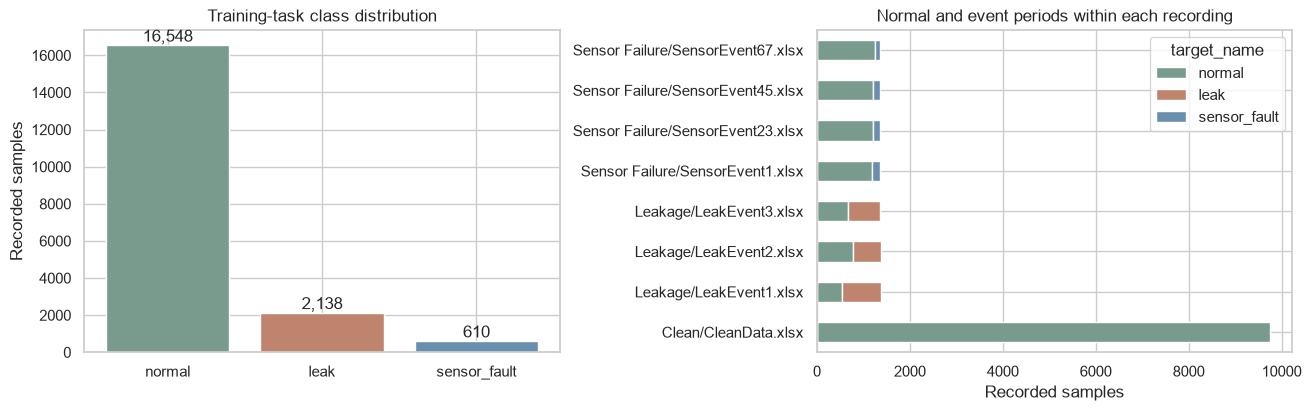

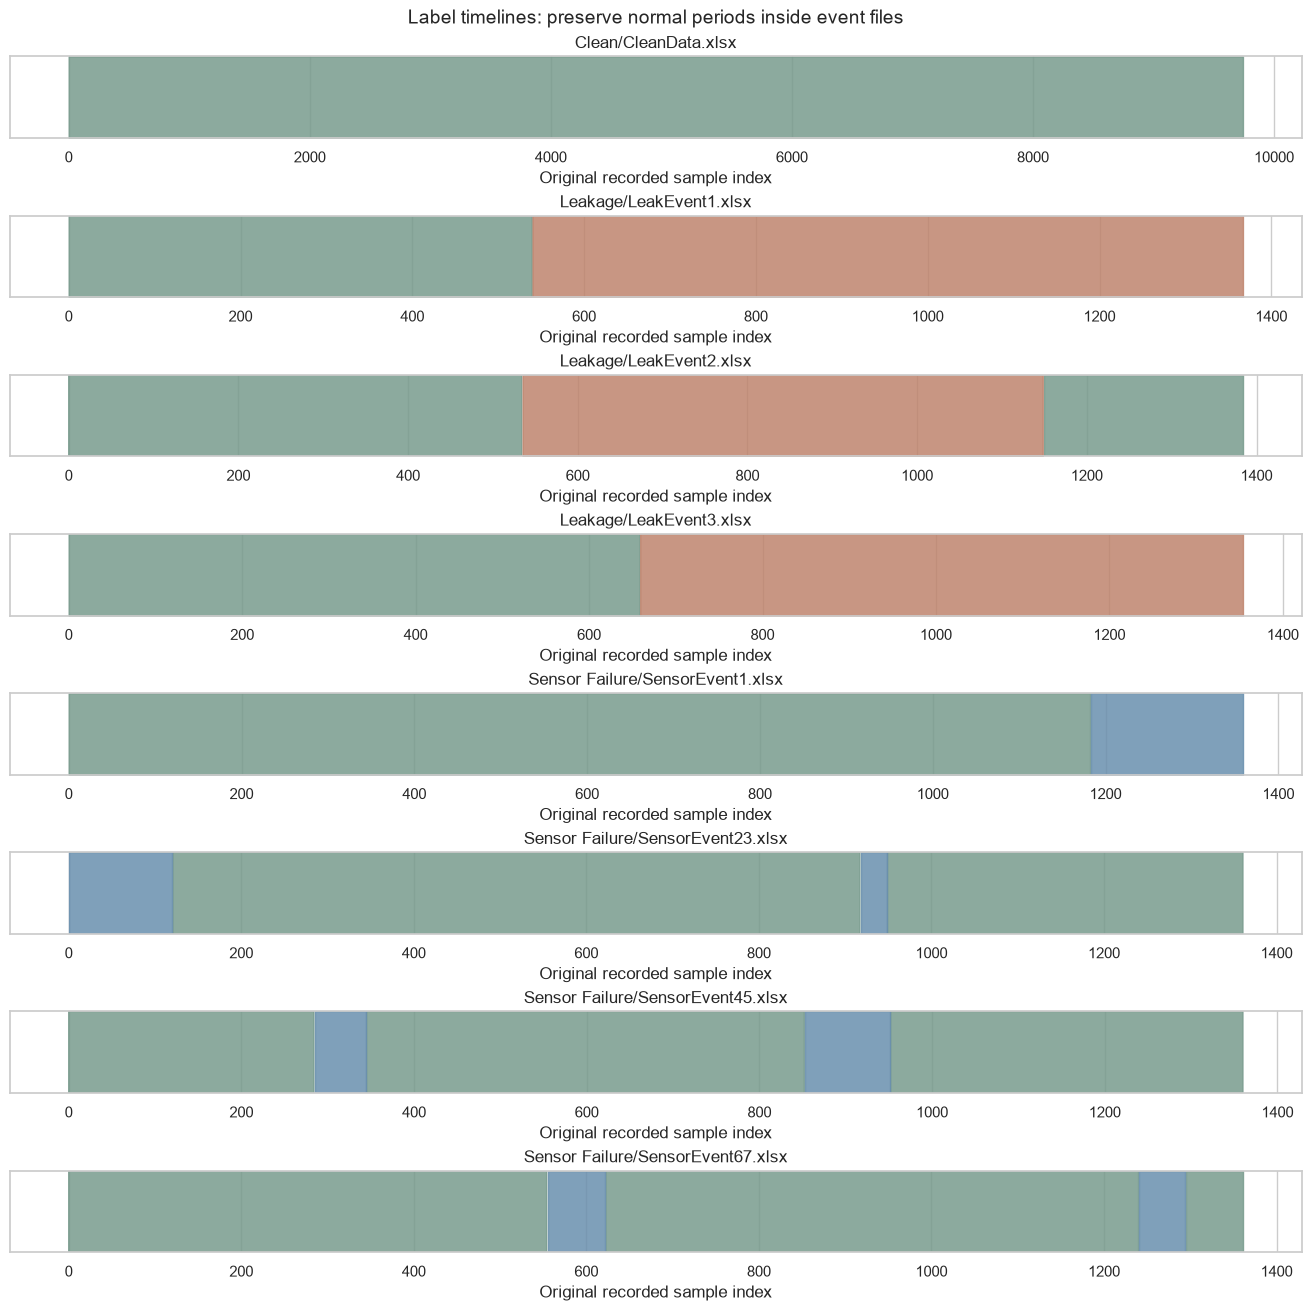

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4), constrained_layout=True)
counts = combined.target_name.value_counts().reindex(CLASS_NAMES, fill_value=0)
axes[0].bar(counts.index, counts.values, color=[COLOURS[c] for c in counts.index])
axes[0].set(title="Training-task class distribution", ylabel="Recorded samples")
for i, n in enumerate(counts.values):
    axes[0].text(i, n, f"{n:,}", ha="center", va="bottom")
normal_by_file = pd.crosstab(combined.recording_id, combined.target_name).reindex(columns=CLASS_NAMES, fill_value=0)
normal_by_file.plot.barh(stacked=True, ax=axes[1], color=[COLOURS[c] for c in CLASS_NAMES])
axes[1].set(title="Normal and event periods within each recording", xlabel="Recorded samples", ylabel="")
plt.show()

fig, axes = plt.subplots(len(parts), 1, figsize=(13, 13), constrained_layout=True)
for ax, frame in zip(axes, parts):
    x = frame.sample_index.to_numpy()
    for cid in CLASS_IDS:
        ax.fill_between(x, 0, 1, where=frame.target.eq(cid).to_numpy(),
            color=COLOURS[CLASS_MAP[cid]], step="mid", alpha=.85)
    ax.set(title=frame.recording_id.iloc[0], yticks=[], ylim=(0, 1), xlabel="Original recorded sample index")
fig.suptitle("Label timelines: preserve normal periods inside event files", fontsize=14)
plt.show()


## 5. Lock the final test recordings

The following split is chosen by recording name before fitting any model. It is not an exact 70/30 or 80/20 split: those requested ratios are applied later **within development data**. The final test includes normal periods and event periods from both held-out recordings.

We audit exact feature-vector overlap, but do not remove legitimate repeated physical readings just to improve scores. Six development recordings and two final-test recordings remain completely separate. This is a small laboratory benchmark; report the number of recordings alongside sample counts.


In [6]:
missing_holdouts = set(FINAL_TEST_RECORDINGS) - set(combined.recording_id)
if missing_holdouts:
    raise ValueError(f"Final-test recordings are missing: {missing_holdouts}")
final_mask = combined.recording_id.isin(FINAL_TEST_RECORDINGS)
development = combined.loc[~final_mask].copy().reset_index(drop=True)
final_test = combined.loc[final_mask].copy().reset_index(drop=True)
assert set(development.recording_id).isdisjoint(final_test.recording_id)
assert set(development.target) == set(final_test.target) == set(CLASS_IDS)
X_dev, y_dev = development[FEATURES], development.target
X_final, y_final = final_test[FEATURES], final_test.target
assert not set(FEATURES) & {"target", "target_name", "Labels", "original_label", "recording_id", "source_category", "sample_index"}

membership = source_audit[["recording_id", "kept_rows", "normal", "leak", "sensor_fault"]].copy()
membership["role"] = np.where(membership.recording_id.isin(FINAL_TEST_RECORDINGS), "untouched_final_test", "development")
display(membership)
display(pd.DataFrame({"development": development.target_name.value_counts(), "final_test": final_test.target_name.value_counts()}).fillna(0).astype(int).reindex(CLASS_NAMES))
dev_hashes = set(pd.util.hash_pandas_object(X_dev, index=False))
exact_overlap = pd.util.hash_pandas_object(X_final, index=False).isin(dev_hashes)
print("Final-test samples whose exact feature vector also occurs in development:", int(exact_overlap.sum()))
print("These may be repeated/quantised normal readings; file separation is enforced independently.")
membership.to_csv(OUTPUT_DIR / "recording_roles.csv", index=False)


,recording_id,kept_rows,normal,leak,sensor_fault,role
0,Clean/CleanData.xlsx,9743,9743,0,0,development
1,Leakage/LeakEvent1.xlsx,1368,540,828,0,development
2,Leakage/LeakEvent2.xlsx,1385,771,614,0,development
3,Leakage/LeakEvent3.xlsx,1355,659,696,0,untouched_final_test
4,Sensor Failure/SensorEvent1.xlsx,1360,1183,0,177,development
5,Sensor Failure/SensorEvent23.xlsx,1362,1210,0,152,development
6,Sensor Failure/SensorEvent45.xlsx,1361,1202,0,159,development
7,Sensor Failure/SensorEvent67.xlsx,1362,1240,0,122,untouched_final_test


,development,final_test
target_name,,
normal,14649,1899
leak,1442,696
sensor_fault,488,122


Final-test samples whose exact feature vector also occurs in development: 0
These may be repeated/quantised normal readings; file separation is enforced independently.


## 6. Pipelines and scoring

Logistic Regression uses training-fold median imputation and scaling. Random Forest uses training-fold median imputation and does not require scaling. Both use balanced class weights because normal samples dominate. No SMOTE or fabricated sensor readings are introduced.

Report accuracy, macro/weighted F1, per-class precision and recall, one-vs-rest macro ROC AUC, leak average precision, and false-leak alarm rate. Model scores from `predict_proba` are uncalibrated scores, not verified probabilities of a real pipe leak.


In [7]:
def make_pipeline(name):
    steps = [("imputer", SimpleImputer(strategy="median", keep_empty_features=True))]
    if name == "Logistic Regression":
        steps += [("scaler", StandardScaler()), ("classifier", LogisticRegression(
            solver="lbfgs", C=1.0, max_iter=3000, class_weight="balanced", random_state=SEED))]
    elif name == "Random Forest":
        steps += [("classifier", RandomForestClassifier(n_estimators=RF_TREES,
            min_samples_leaf=3, class_weight="balanced", random_state=SEED, n_jobs=1))]
    else:
        raise ValueError(name)
    return Pipeline(steps)

PARAM_GRIDS = {"Logistic Regression": {"classifier__C": [0.1, 1.0, 10.0]},
    "Random Forest": {"classifier__max_depth": [8, None], "classifier__min_samples_leaf": [1, 5]}}
MODEL_NAMES = list(PARAM_GRIDS)

def metrics(y_true, y_pred, probabilities):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    precision, recall, f1, support = precision_recall_fscore_support(y_true, y_pred, labels=CLASS_IDS, zero_division=0)
    values = {"accuracy": float(accuracy_score(y_true, y_pred)),
        "macro_f1_present_classes": float(f1_score(y_true, y_pred, labels=np.unique(y_true), average="macro", zero_division=0)),
        "macro_f1": float(f1_score(y_true, y_pred, labels=CLASS_IDS, average="macro", zero_division=0)),
        "weighted_f1": float(f1_score(y_true, y_pred, labels=CLASS_IDS, average="weighted", zero_division=0))}
    for i, name in enumerate(CLASS_NAMES):
        values.update({f"{name}_precision": float(precision[i]), f"{name}_recall": float(recall[i]) if support[i] else None,
            f"{name}_f1": float(f1[i]), f"{name}_support": int(support[i])})
    non_leak = y_true != 1
    normal = y_true == 0
    faults = y_true == 2
    values["false_leak_rate_nonleak"] = float(np.mean(y_pred[non_leak] == 1)) if non_leak.any() else None
    values["false_event_rate_normal"] = float(np.mean(y_pred[normal] != 0)) if normal.any() else None
    values["sensor_fault_predicted_leak_rate"] = float(np.mean(y_pred[faults] == 1)) if faults.any() else None
    values["macro_roc_auc_ovr"] = float(roc_auc_score(y_true, probabilities, labels=CLASS_IDS, multi_class="ovr", average="macro")) if len(np.unique(y_true)) == 3 else None
    values["leak_average_precision"] = float(average_precision_score(y_true == 1, probabilities[:, 1])) if (y_true == 1).any() else None
    return values

def predict_aligned(estimator, X):
    probabilities = estimator.predict_proba(X)
    classes = list(estimator.classes_)
    assert classes == CLASS_IDS, f"Unexpected class order {classes}"
    return estimator.predict(X), probabilities

def overlap_rows(X_train, X_test):
    seen = set(pd.util.hash_pandas_object(X_train, index=False))
    return int(pd.util.hash_pandas_object(X_test, index=False).isin(seen).sum())

def stratified_cv(y, folds):
    if pd.Series(y).value_counts().min() < folds:
        raise ValueError("Not enough samples per class for the requested CV")
    return StratifiedKFold(n_splits=folds, shuffle=True, random_state=SEED)


## 7. Run all 16 requested model/configuration comparisons

The same split seed is used for both models. Split-only runs have no CV score. CV-only runs have out-of-fold scores, not a separate holdout score. Split + CV rows show the tuned training-CV mean and the separate development-test performance. **Do not select the deployment model by taking the largest score across these different score types.**

Each completed experiment is saved to CSV, so partial progress is available while Colab runs. Random Forest uses one worker per fit; CV uses at most two workers to avoid nesting parallel jobs.


In [8]:
CONFIGURATIONS = [
    ("70/30", .30, None), ("80/20", .20, None),
    ("CV 5", None, 5), ("CV 10", None, 10),
    ("70/30 + CV 5", .30, 5), ("70/30 + CV 10", .30, 10),
    ("80/20 + CV 5", .20, 5), ("80/20 + CV 10", .20, 10)]
results, fold_records, split_records, comparison_reports = [], [], [], {}
for model_name in MODEL_NAMES:
    for config_name, test_fraction, folds in CONFIGURATIONS:
        number = len(results) + 1
        message = f"[{number:02d}/16] {model_name} | {config_name}"
        print(message, flush=True)
        with (OUTPUT_DIR / "progress.log").open("a", encoding="utf-8") as stream:
            stream.write(message + "\n")
        start = time.perf_counter()
        cv_mean = cv_std = None
        best_params = {}
        if test_fraction is not None:
            train_idx, test_idx = train_test_split(np.arange(len(X_dev)), test_size=test_fraction,
                stratify=y_dev, random_state=SEED)
            X_train, X_eval = X_dev.iloc[train_idx], X_dev.iloc[test_idx]
            y_train, y_eval = y_dev.iloc[train_idx], y_dev.iloc[test_idx]
            estimator = make_pipeline(model_name)
            if folds:
                splits = list(stratified_cv(y_train, folds).split(X_train, y_train))
                search = GridSearchCV(estimator, PARAM_GRIDS[model_name], cv=splits,
                    scoring="f1_macro", refit=True, n_jobs=CV_JOBS, error_score="raise")
                search.fit(X_train, y_train)
                estimator = search.best_estimator_
                best_params = search.best_params_
                cv_mean = float(search.best_score_)
                cv_std = float(search.cv_results_["std_test_score"][search.best_index_])
                for fold, (tr, va) in enumerate(splits, start=1):
                    score = float(search.cv_results_[f"split{fold-1}_test_score"][search.best_index_])
                    fold_records.append({"model": model_name, "configuration": config_name,
                        "fold": fold, "train_samples": len(tr), "validation_samples": len(va),
                        "macro_f1": score, "scope": "CV inside development training portion"})
            else:
                estimator.fit(X_train, y_train)
            pred, proba = predict_aligned(estimator, X_eval)
            score_basis = "development holdout"
            n_train, n_eval = len(train_idx), len(test_idx)
            overlap = overlap_rows(X_train, X_eval)
            split_records.append({"configuration": config_name, "model": model_name,
                "train_samples": n_train, "evaluation_samples": n_eval,
                "train_fraction_actual": n_train / len(X_dev), "evaluation_fraction_actual": n_eval / len(X_dev),
                "recordings_shared": len(set(development.iloc[train_idx].recording_id) & set(development.iloc[test_idx].recording_id)),
                "evaluation_exact_vectors_in_training": overlap, "protocol": "stratified samples; exploratory"})
        else:
            splits = list(stratified_cv(y_dev, folds).split(X_dev, y_dev))
            proba = cross_val_predict(make_pipeline(model_name), X_dev, y_dev, cv=splits,
                method="predict_proba", n_jobs=CV_JOBS)
            pred = np.asarray(CLASS_IDS)[proba.argmax(axis=1)]
            y_eval = y_dev
            fold_scores = []
            for fold, (tr, va) in enumerate(splits, start=1):
                score = float(f1_score(y_dev.iloc[va], pred[va], labels=CLASS_IDS, average="macro", zero_division=0))
                fold_scores.append(score)
                fold_records.append({"model": model_name, "configuration": config_name,
                    "fold": fold, "train_samples": len(tr), "validation_samples": len(va),
                    "macro_f1": score, "scope": "development out-of-fold samples"})
                split_records.append({"configuration": config_name, "model": model_name,
                    "fold": fold, "train_samples": len(tr), "evaluation_samples": len(va),
                    "recordings_shared": len(set(development.iloc[tr].recording_id) & set(development.iloc[va].recording_id)),
                    "evaluation_exact_vectors_in_training": overlap_rows(X_dev.iloc[tr], X_dev.iloc[va]),
                    "protocol": "stratified samples; exploratory"})
            cv_mean, cv_std = float(np.mean(fold_scores)), float(np.std(fold_scores))
            score_basis = "development out-of-fold"
            n_train, n_eval = None, len(y_eval)
        score = metrics(y_eval, pred, proba)
        results.append({"model": model_name, "configuration": config_name, "score_basis": score_basis,
            "train_samples": n_train, "evaluated_samples": n_eval, "cv_folds": folds,
            "cv_macro_f1_mean": cv_mean, "cv_macro_f1_std": cv_std,
            "best_params": json.dumps(best_params), "seconds": time.perf_counter() - start, **score})
        comparison_reports[f"{model_name} | {config_name}"] = {
            "classification_report": classification_report(y_eval, pred, labels=CLASS_IDS, target_names=CLASS_NAMES, output_dict=True, zero_division=0),
            "confusion_matrix": confusion_matrix(y_eval, pred, labels=CLASS_IDS).tolist()}
        pd.DataFrame(results).to_csv(OUTPUT_DIR / "comparison.csv", index=False)
        pd.DataFrame(fold_records).to_csv(OUTPUT_DIR / "fold_metrics.csv", index=False)
        pd.DataFrame(split_records).to_csv(OUTPUT_DIR / "split_audit.csv", index=False)
        print(f"  accuracy={score['accuracy']:.4f}, macro F1={score['macro_f1']:.4f}, leak recall={score['leak_recall']:.4f}", flush=True)

comparison = pd.DataFrame(results)
assert len(comparison) == 16
display(comparison[["model", "configuration", "score_basis", "accuracy", "macro_f1", "leak_precision", "leak_recall", "sensor_fault_recall", "cv_macro_f1_mean", "cv_macro_f1_std"]].round(4))
(OUTPUT_DIR / "comparison_reports.json").write_text(json.dumps(comparison_reports, indent=2), encoding="utf-8")


[01/16] Logistic Regression | 70/30


  accuracy=0.9280, macro F1=0.7875, leak recall=0.9931

[02/16] Logistic Regression | 80/20


  accuracy=0.9309, macro F1=0.7916, leak recall=1.0000


[03/16] Logistic Regression | CV 5


...

  accuracy=0.9925, macro F1=0.9589, leak recall=1.0000


[16/16] Random Forest | 80/20 + CV 10


  accuracy=0.9925, macro F1=0.9589, leak recall=1.0000


,model,configuration,score_basis,accuracy,macro_f1,leak_precision,leak_recall,sensor_fault_recall,cv_macro_f1_mean,cv_macro_f1_std
0,Logistic Regression,70/30,development holdout,0.9280,0.7875,0.9751,0.9931,0.8562,NaN,NaN
1,Logistic Regression,80/20,development holdout,0.9309,0.7916,0.9730,1.0000,0.8469,NaN,NaN
2,Logistic Regression,CV 5,development out-of-fold,0.9292,0.7889,0.9735,0.9951,0.8504,0.7919,0.0226
3,Logistic Regression,CV 10,development out-of-fold,0.9289,0.7884,0.9703,0.9951,0.8525,0.7899,0.0149
4,Logistic Regression,70/30 + CV 5,development holdout,0.9318,0.7926,0.9795,0.9931,0.8493,0.8044,0.0120
5,Logistic Regression,70/30 + CV 10,development holdout,0.9318,0.7926,0.9795,0.9931,0.8493,0.8042,0.0140
6,Logistic Regression,80/20 + CV 5,development holdout,0.9349,0.7977,0.9796,1.0000,0.8469,0.7974,0.0171
7,Logistic Regression,80/20 + CV 10,development holdout,0.9349,0.7977,0.9796,1.0000,0.8469,0.8009,0.0116
8,Random Forest,70/30,development holdout,0.9914,0.9542,0.9954,1.0000,0.9384,NaN,NaN
9,Random Forest,80/20,development holdout,0.9913,0.9553,0.9897,1.0000,0.9388,NaN,NaN


18652

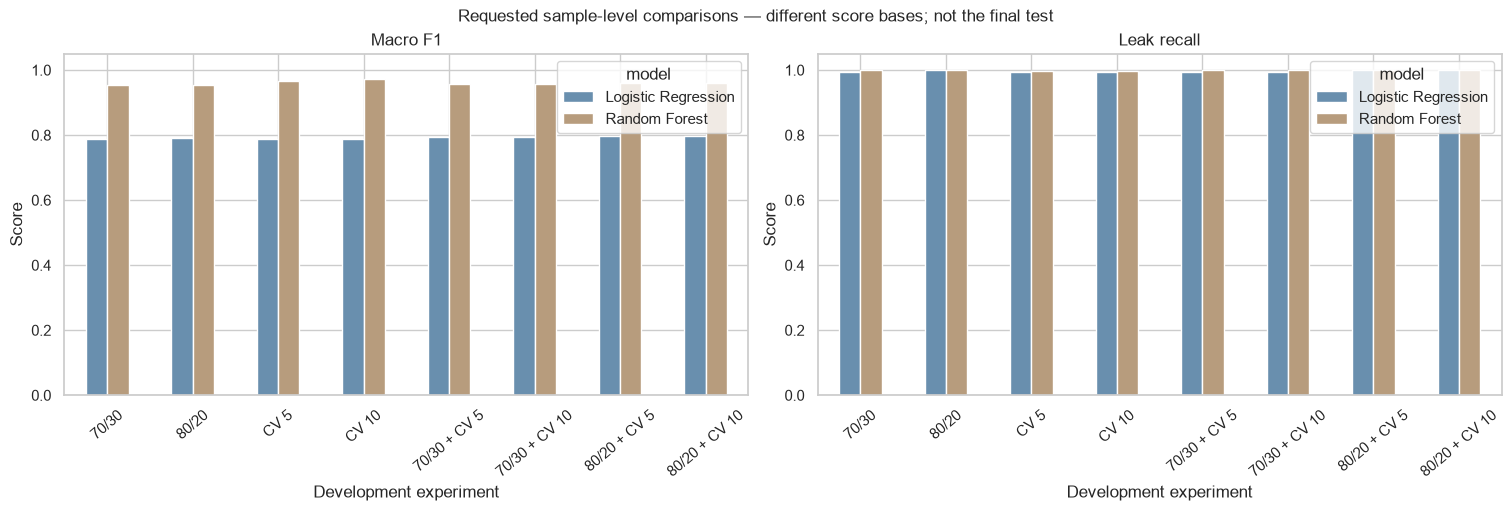

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)
config_order = [c[0] for c in CONFIGURATIONS]
for ax, metric, title in zip(axes, ["macro_f1", "leak_recall"], ["Macro F1", "Leak recall"]):
    chart = comparison.pivot(index="configuration", columns="model", values=metric).reindex(config_order)
    chart.plot.bar(ax=ax, color=["#698fae", "#b79c7d"], rot=40)
    ax.set(title=title, ylim=(0, 1.05), xlabel="Development experiment", ylabel="Score")
fig.suptitle("Requested sample-level comparisons — different score bases; not the final test", fontsize=12)
plt.show()


## 8. Select the model using a common development protocol

Both model families now receive the same shared five-fold development splits and are tuned on the same objective: macro F1. This step chooses the candidate **before opening final-test predictions**. Hyperparameter-search CV scores are model-selection scores, not independent final performance estimates.

The pipelines below fit all six development recordings after CV. They remain untrained on both reserved recordings. We keep these models for the app export instead of refitting on the final test and attaching an incompatible evaluation score.


In [10]:
selection_splits = list(stratified_cv(y_dev, 5).split(X_dev, y_dev))
selection_rows, fitted_models = [], {}
for model_name in MODEL_NAMES:
    print("Shared model-selection search:", model_name, flush=True)
    search = GridSearchCV(make_pipeline(model_name), PARAM_GRIDS[model_name], cv=selection_splits,
        scoring="f1_macro", refit=True, n_jobs=CV_JOBS, error_score="raise")
    search.fit(X_dev, y_dev)
    fitted_models[model_name] = search.best_estimator_
    selection_rows.append({"model": model_name, "selection_cv_macro_f1": float(search.best_score_),
        "selection_cv_std": float(search.cv_results_["std_test_score"][search.best_index_]),
        "best_params": json.dumps(search.best_params_)})
selection = pd.DataFrame(selection_rows).sort_values("selection_cv_macro_f1", ascending=False)
selected_name = selection.iloc[0]["model"]  # Locked BEFORE evaluating final_test.
selection.to_csv(OUTPUT_DIR / "model_selection_cv.csv", index=False)
display(selection)
print("Locked model selection:", selected_name)


Shared model-selection search: Logistic Regression


Shared model-selection search: Random Forest


,model,selection_cv_macro_f1,selection_cv_std,best_params
1,Random Forest,0.981264,0.003483,"{""classifier__max_depth"": null, ""classifier__min_samples_leaf"": 1}"
0,Logistic Regression,0.797584,0.027308,"{""classifier__C"": 0.1}"


Locked model selection: Random Forest


## 9. Final test on the two unseen recordings

Evaluate both already-fitted candidates to document generalisation; keep the selection from the previous cell. Do not switch winners, retune thresholds or rerun hyperparameter selection based on this test. If you use these results to redesign the model later, this test becomes development evidence and a new independent test is needed for a fresh unbiased claim.

The sensor-failure recording may involve a different failed channel from those seen during training. A drop from row-level CV to this recording-level test is valuable evidence about robustness; report it rather than replacing it with the highest CV number.


In [11]:
final_rows, final_reports, final_predictions = [], {}, {}
for model_name, estimator in fitted_models.items():
    pred, proba = predict_aligned(estimator, X_final)
    final_predictions[model_name] = (pred, proba)
    final_rows.append({"model": model_name, "selected_before_test": model_name == selected_name,
        "test_samples": len(y_final), **metrics(y_final, pred, proba)})
    report = classification_report(y_final, pred, labels=CLASS_IDS, target_names=CLASS_NAMES, output_dict=True, zero_division=0)
    final_reports[model_name] = {"classification_report": report,
        "confusion_matrix": confusion_matrix(y_final, pred, labels=CLASS_IDS).tolist()}
    print("\n", model_name)
    print(classification_report(y_final, pred, labels=CLASS_IDS, target_names=CLASS_NAMES, zero_division=0))
final_results = pd.DataFrame(final_rows)
display(final_results[["model", "selected_before_test", "accuracy", "macro_f1", "leak_precision", "leak_recall", "sensor_fault_precision", "sensor_fault_recall", "false_leak_rate_nonleak"]].round(4))
final_results.to_csv(OUTPUT_DIR / "final_recording_test.csv", index=False)
(OUTPUT_DIR / "final_test_reports.json").write_text(json.dumps(final_reports, indent=2), encoding="utf-8")
selected_test = final_results.loc[final_results.model.eq(selected_name)].iloc[0]
print("\nBaseline interpretation")
print("Selected development-CV macro F1:", round(float(selection.iloc[0].selection_cv_macro_f1), 4))
print("Selected unseen-recording macro F1:", round(float(selected_test.macro_f1), 4))
for event_name in ["leak", "sensor_fault"]:
    support = int(selected_test[f"{event_name}_support"])
    detected = int(round(float(selected_test[f"{event_name}_recall"]) * support))
    print(f"{event_name}: {detected}/{support} final-test event samples classified correctly.")
    if support and detected == 0:
        print("  This candidate missed all samples of that event type in this test.")
print("Exports are experimental baselines. Review this gap before enabling automatic detection in the app.")



 Logistic Regression
              precision    recall  f1-score   support

      normal       0.92      0.69      0.79      1899
        leak       0.95      1.00      0.97       696
sensor_fault       0.01      0.06      0.02       122

    accuracy                           0.74      2717
   macro avg       0.63      0.58      0.59      2717
weighted avg       0.89      0.74      0.80      2717


 Random Forest
              precision    recall  f1-score   support

      normal       0.70      0.99      0.82      1899
        leak       0.00      0.00      0.00       696
sensor_fault       0.00      0.00      0.00       122

    accuracy                           0.69      2717
   macro avg       0.23      0.33      0.27      2717
weighted avg       0.49      0.69      0.57      2717



,model,selected_before_test,accuracy,macro_f1,leak_precision,leak_recall,sensor_fault_precision,sensor_fault_recall,false_leak_rate_nonleak
0,Logistic Regression,False,0.7431,0.5944,0.9457,1.0,0.0127,0.0574,0.0198
1,Random Forest,True,0.6908,0.2724,0.0000,0.0,0.0000,0.0000,0.0000



Baseline interpretation
Selected development-CV macro F1: 0.9813
Selected unseen-recording macro F1: 0.2724
leak: 0/696 final-test event samples classified correctly.
  This candidate missed all samples of that event type in this test.
sensor_fault: 0/122 final-test event samples classified correctly.
  This candidate missed all samples of that event type in this test.
Exports are experimental baselines. Review this gap before enabling automatic detection in the app.


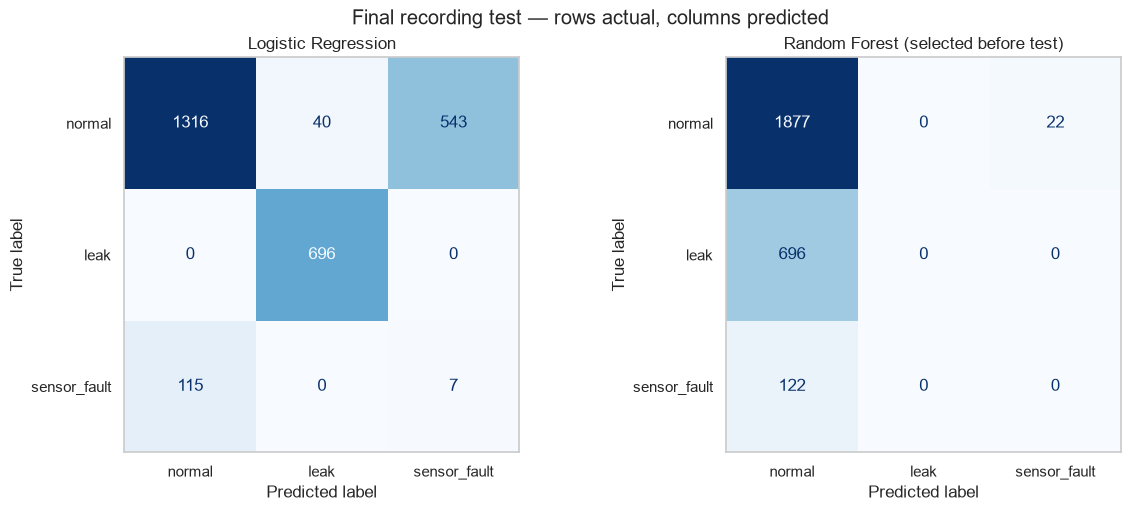

,model,recording_id,accuracy,macro_f1_present_classes,leak_recall,sensor_fault_recall
0,Logistic Regression,Leakage/LeakEvent3.xlsx,0.7218,0.7857,1.0,NaN
1,Logistic Regression,Sensor Failure/SensorEvent67.xlsx,0.7643,0.4537,NaN,0.0574
2,Random Forest,Leakage/LeakEvent3.xlsx,0.4863,0.3272,0.0,NaN
3,Random Forest,Sensor Failure/SensorEvent67.xlsx,0.8943,0.4721,NaN,0.0000


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5), constrained_layout=True)
for ax, name in zip(axes, MODEL_NAMES):
    pred, _ = final_predictions[name]
    ConfusionMatrixDisplay.from_predictions(y_final, pred, labels=CLASS_IDS, display_labels=CLASS_NAMES,
        ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.grid(False)
    ax.set_title(name + (" (selected before test)" if name == selected_name else ""))
fig.suptitle("Final recording test — rows actual, columns predicted")
plt.show()

per_recording = []
for name, (pred, proba) in final_predictions.items():
    for rid in FINAL_TEST_RECORDINGS:
        mask = final_test.recording_id.eq(rid).to_numpy()
        per_recording.append({"model": name, "recording_id": rid, "samples": int(mask.sum()),
            **metrics(y_final[mask], pred[mask], proba[mask])})
per_recording_results = pd.DataFrame(per_recording)
display(per_recording_results[["model", "recording_id", "accuracy", "macro_f1_present_classes", "leak_recall", "sensor_fault_recall"]].round(4))
per_recording_results.to_csv(OUTPUT_DIR / "per_recording_test.csv", index=False)


## 10. Recorded event detection and false alarms

Report per-sample classification **and** first detection of each labelled event segment. The authors document one sample per second, so sample offsets are source-time seconds here. A predicted class once is the event-detection criterion; this is not a production alarm policy and does not include persistence checks or network delay. Missed events stay `missed`, never zero-second detections.

Only two held-out recordings are evaluated, so do not generalise these few event delays to an entire township. No leak volume, repair time, cost saving or calibrated leak probability is estimated.


In [13]:
event_rows = []
for name, (pred, proba) in final_predictions.items():
    prediction_frame = final_test[["recording_id", "sample_index", "target", "target_name"]].copy()
    prediction_frame["predicted_class"] = pred
    for i, cname in enumerate(CLASS_NAMES):
        prediction_frame[f"score_{cname}"] = proba[:, i]
    prediction_frame.to_csv(OUTPUT_DIR / ("predictions_" + name.lower().replace(" ", "_") + ".csv"), index=False)
    for rid, group in prediction_frame.groupby("recording_id", sort=False):
        group = group.sort_values("sample_index")
        segment_id = group.target.ne(group.target.shift()).cumsum()
        for _, segment in group.groupby(segment_id):
            cid = int(segment.target.iloc[0])
            if cid == 0:
                continue
            correct = segment.loc[segment.predicted_class.eq(cid), "sample_index"]
            onset = int(segment.sample_index.iloc[0])
            first = int(correct.iloc[0]) if len(correct) else None
            event_rows.append({"model": name, "recording_id": rid, "event": CLASS_MAP[cid],
                "start_sample": onset, "end_sample": int(segment.sample_index.iloc[-1]),
                "detected": first is not None, "first_correct_sample": first,
                "recorded_detection_delay_seconds": first - onset if first is not None else None})
event_detection = pd.DataFrame(event_rows)
display(event_detection)
event_detection.to_csv(OUTPUT_DIR / "event_detection.csv", index=False)


,model,recording_id,event,start_sample,end_sample,detected,first_correct_sample,recorded_detection_delay_seconds
0,Logistic Regression,Leakage/LeakEvent3.xlsx,leak,659,1354,True,659.0,0.0
1,Logistic Regression,Sensor Failure/SensorEvent67.xlsx,sensor_fault,555,622,True,580.0,25.0
2,Logistic Regression,Sensor Failure/SensorEvent67.xlsx,sensor_fault,1241,1294,False,NaN,NaN
3,Random Forest,Leakage/LeakEvent3.xlsx,leak,659,1354,False,NaN,NaN
4,Random Forest,Sensor Failure/SensorEvent67.xlsx,sensor_fault,555,622,False,NaN,NaN
5,Random Forest,Sensor Failure/SensorEvent67.xlsx,sensor_fault,1241,1294,False,NaN,NaN


## 11. Export portable models and the app evaluation file

Export both candidate pipelines, plus the model chosen **by development CV** as `models/monitor.joblib`. Each bundle contains the fitted built-in scikit-learn pipeline, eight ordered raw input features, the class mapping and version information. No custom notebook function is pickled, and scaling/imputation travel with the estimator.

`models/evaluation.json` reports the selected model's **unseen-recording final test**, not its training/CV accuracy. The inference bundle is fitted only on the six development recordings, matching this evaluation. The original test recordings stay unseen.

Download the ZIP, copy `monitor.joblib` and `evaluation.json` into the existing project's `models` folder, then use **Settings → Reload model**. The notebook also exports `model_runtime_requirements.txt` and records package versions; match the app's scikit-learn version before loading. Only load model bundles produced by your team because joblib uses Python pickle.

The score is an uncalibrated classifier score. If final-test results are inadequate, keep the model as an experimental prototype and improve it before making deployment claims.


In [14]:
delivery = OUTPUT_DIR / "delivery"
model_dir = delivery / "models"
model_dir.mkdir(parents=True, exist_ok=True)
version = "wdseventdb-three-class-v1"
provenance = {"source": DATA_URL, "features": FEATURES, "class_map": CLASS_MAP,
    "training_recordings": sorted(development.recording_id.unique()), "final_test_recordings": FINAL_TEST_RECORDINGS,
    "selection": "shared stratified 5-fold development CV; best macro F1", "selected_model": selected_name,
    "versions": VERSIONS, "source_audit": source_audit.to_dict(orient="records"),
    "requested_comparison_scope": "stratified samples from development recordings only"}
for name, estimator in fitted_models.items():
    bundle = {"model": estimator, "features": FEATURES, "class_map": {str(k): v for k, v in CLASS_MAP.items()},
        "version": version + "-" + name.lower().replace(" ", "-"), "model_name": name, "runtime_versions": VERSIONS,
        "training_recordings": provenance["training_recordings"], "final_test_recordings": FINAL_TEST_RECORDINGS,
        "deployment_status": "experimental_baseline"}
    joblib.dump(bundle, model_dir / (name.lower().replace(" ", "_") + ".joblib"), compress=3)
    if name == selected_name:
        joblib.dump(bundle, model_dir / "monitor.joblib", compress=3)

selected_row = final_results.loc[final_results.model.eq(selected_name)].iloc[0]
selected_cm = final_reports[selected_name]["confusion_matrix"]
selected_bundle = joblib.load(model_dir / "monitor.joblib")
evaluation = {"model_version": selected_bundle["version"],
    "split_description": "Unseen recordings LeakEvent3.xlsx and SensorEvent67.xlsx; model selected using development CV and fitted only on six development recordings.",
    "samples": int(len(y_final)), "accuracy": float(selected_row.accuracy), "macro_f1": float(selected_row.macro_f1),
    "class_names": CLASS_NAMES, "confusion_matrix": selected_cm, "model_name": selected_name,
    "test_recordings": FINAL_TEST_RECORDINGS, "training_recordings": provenance["training_recordings"],
    "per_class": final_reports[selected_name]["classification_report"], "runtime_versions": VERSIONS,
    "deployment_status": "experimental_baseline",
    "leak_recall": float(selected_row.leak_recall), "sensor_fault_recall": float(selected_row.sensor_fault_recall),
    "score_note": "Laboratory recording test, not SDP field accuracy."}
assert sum(map(sum, selected_cm)) == evaluation["samples"]
assert math.isclose(sum(selected_cm[i][i] for i in CLASS_IDS) / evaluation["samples"], evaluation["accuracy"])
(model_dir / "evaluation.json").write_text(json.dumps(evaluation, indent=2, allow_nan=False), encoding="utf-8")
(delivery / "training_manifest.json").write_text(json.dumps(provenance, indent=2), encoding="utf-8")
(delivery / "model_runtime_requirements.txt").write_text(
    "\n".join(f"{package}=={VERSIONS[key]}" for package, key in
        [("scikit-learn", "sklearn"), ("numpy", "numpy"), ("pandas", "pandas"), ("joblib", "joblib")]) + "\n", encoding="utf-8")
(delivery / "READ_ME_FIRST.txt").write_text(
    "EXPERIMENTAL BASELINE EXPORT\n"
    f"Selected by development CV: {selected_name}\n"
    f"Unseen-recording macro F1: {evaluation['macro_f1']:.4f}\n"
    f"Unseen-recording leak recall: {evaluation['leak_recall']:.4f}\n"
    f"Unseen-recording sensor-fault recall: {evaluation['sensor_fault_recall']:.4f}\n"
    "Review final_recording_test.csv and confusion matrices before app integration.\n"
    "Interface compatibility does not establish detection quality.\n", encoding="utf-8")
for filename in ["combined_cleaned.csv", "comparison.csv", "fold_metrics.csv", "split_audit.csv", "source_audit.csv", "cleaning_log.csv",
    "feature_audit.csv", "recording_roles.csv", "model_selection_cv.csv", "final_recording_test.csv", "per_recording_test.csv",
    "event_detection.csv", "comparison_reports.json", "final_test_reports.json"]:
    shutil.copy2(OUTPUT_DIR / filename, delivery / filename)

# Freshly loaded pipeline must predict identically and match the app's input contract.
probe = X_final.iloc[:20].copy()
np.testing.assert_array_equal(selected_bundle["model"].predict(probe), fitted_models[selected_name].predict(probe))
assert selected_bundle["features"] == FEATURES
assert set(selected_bundle["class_map"].values()) <= {"normal", "leak", "sensor_fault", "review"}
print("Selected model:", selected_name)
print("Final-test accuracy:", round(evaluation["accuracy"], 4), "| macro F1:", round(evaluation["macro_f1"], 4))
print("Joblib round-trip and app export schema checks passed.")


Selected model: Random Forest
Final-test accuracy: 0.6908 | macro F1: 0.2724
Joblib round-trip and app export schema checks passed.


In [15]:
archive_path = Path(shutil.make_archive(str(OUTPUT_DIR / "water_guardian_model_package"), "zip", delivery))
print("Model package:", archive_path.name)
print("Optional combined dataset:", (OUTPUT_DIR / "combined_cleaned.csv").name)
if IN_COLAB:
    from google.colab import files
    files.download(str(archive_path))


Model package: water_guardian_model_package.zip
Optional combined dataset: combined_cleaned.csv


## 12. What to put in your proposal and demo

* Explain that eight real laboratory recordings were stacked into one table, keeping per-sample event labels and recording provenance.
* Report cleaning actions from the audit, not a generic claim that everything was cleaned. State that fault signatures and legitimate repeated readings were retained.
* Show both models across the eight requested **development** configurations, with CV and development-test columns labelled separately.
* Present the reserved-recording confusion matrices, leak recall/precision, sensor-fault recall, normal false alarms and recorded detection delays as the main performance evidence.
* State that the selected model was chosen using development CV before the final test. Small laboratory-recording performance is not field validation in an SDP township.
* Connect the selected bundle to the app. The Monitor proposes an event classification; the agents review recorded evidence, draft an inspection and wait for operator approval.

**Not done here:** training on Cyberattack, neural networks, synthetic measurements, new township data collection, pipe localisation or leak-volume estimation. These require separate scope and evidence.

Rerunning this notebook produces a fresh package. Keep the split seed, source hashes, package versions and training manifest with every result you report.
